# 1.Import libraries 

In [1]:
import tensorflow as tf 
from tensorflow.keras.models import Sequential 
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt 
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import numpy as np

I0000 00:00:1779530356.216349    1835 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1779530356.318072    1835 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1779530391.583965    1835 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# 2. Load the dataset

In [3]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

/mnt/d/Github/deep-learning-for-computer-vision/.venv/lib/python3.12/site-packages/keras/src/datasets/cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = cPickle.load(f, encoding="bytes")


In [4]:
class_names = ['Airplane','Automobile','Bird','Cat','Deer','Dog','Frog','Horse','Ship','Truck']

In [5]:
x_train = x_train.astype('float32')/255.0 
x_test = x_test.astype('float32')/255.0

y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# 3. Define the AlexNet model 

In [6]:
model = Sequential() 
# Layer 1 
model.add(Conv2D(96, kernel_size=(3,3), strides=(1,1), input_shape=(32,32,3), padding='same'))
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2,2), strides=(2,2)))
model.add(BatchNormalization())

# Layer 2 
model.add(Conv2D(256, kernel_size=(3,3), strides=(1,1), padding='same')) 
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2,2), strides=(2,2)))
model.add(BatchNormalization())

# Layer 3
model.add(Conv2D(384, kernel_size=(3,3), strides=(1,1), padding='same'))
model.add(Activation('relu'))

# Layer 4
model.add(Conv2D(384, kernel_size=(3,3), strides=(1,1), padding='same'))
model.add(Activation('relu'))

# Layer 5
model.add(Conv2D(256, kernel_size=(3,3), strides=(1,1), padding='same'))
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2,2), strides=(2,2)))

# Flatten
model.add(Flatten())

# Fully Connected Layer 1
model.add(Dense(1024))
model.add(Activation('relu'))
model.add(Dropout(0.5))

# Fully Connected Layer 2
model.add(Dense(512))
model.add(Activation('relu'))
model.add(Dropout(0.5))

# Output Layer
model.add(Dense(10))
model.add(Activation('softmax'))


/mnt/d/Github/deep-learning-for-computer-vision/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1779530416.993072    1835 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1765 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


In [7]:
model.compile(loss='categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy']) 

In [8]:
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)
history = model.fit(x_train, y_train,
                    batch_size=128,
                    epochs=15,
                    callbacks=[early_stop, reduce_lr],
                    validation_split=0.2,
                    verbose=1)

Epoch 1/15


I0000 00:00:1779530421.776860   19085 service.cc:153] XLA service 0x71e1a401ae10 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1779530421.776902   19085 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.5.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1779530421.992928   19085 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1779530422.692140   19085 cuda_dnn.cc:461] Loaded cuDNN version 92101
I0000 00:00:1779530422.840997   19085 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_3996__.58
I0000 00:00:1779530425.814745   19194 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_12', 8540 bytes spill stores, 8520 bytes spill loads

I0000 00:00:1779530426.561731   19194 subprocess_compilation.cc:348] ptxas w

312/313 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.3123 - loss: 1.8647

I0000 00:00:1779530462.646612   19083 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_3996__.58
I0000 00:00:1779530463.721431   19921 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_12', 8416 bytes spill stores, 8424 bytes spill loads

I0000 00:00:1779530464.412299   19924 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_14', 892 bytes spill stores, 892 bytes spill loads

I0000 00:00:1779530465.446518   19924 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_22', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1779530465.721941   19917 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_22', 712 bytes spill stores, 712 bytes spill loads

I0000 00:00:1779530466.592216   19915 subprocess_

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.3126 - loss: 1.8638

I0000 00:00:1779530478.029929   20450 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_8', 780 bytes spill stores, 856 bytes spill loads

W0000 00:00:1779530488.392488   19082 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1020.00MiB (rounded to 1069548032)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1779530488.394575   19082 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1779530488.394581   19082 bfc_allocator.cc:1056] Bin (256): 	Total Chunks: 33, Chunks in use: 33. 8.2KiB allocated for chunks. 8.2KiB in use in bin. 296B client-requested in use in bin.
I0000 00:00:1779530488.394586   19082 bfc_allocator.cc:1056] Bin (512): 	Total Chunks: 11, Chunks in use: 11. 5.5KiB allocated 

313/313 ━━━━━━━━━━━━━━━━━━━━ 77s 178ms/step - accuracy: 0.4152 - loss: 1.5918 - val_accuracy: 0.1343 - val_loss: 7.9056 - learning_rate: 0.0010
Epoch 2/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 21s 66ms/step - accuracy: 0.5987 - loss: 1.1449 - val_accuracy: 0.4213 - val_loss: 1.9400 - learning_rate: 0.0010
Epoch 3/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 23s 75ms/step - accuracy: 0.6784 - loss: 0.9314 - val_accuracy: 0.6255 - val_loss: 1.0693 - learning_rate: 0.0010
Epoch 4/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 24s 75ms/step - accuracy: 0.7293 - loss: 0.7848 - val_accuracy: 0.7125 - val_loss: 0.8435 - learning_rate: 0.0010
Epoch 5/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 21s 66ms/step - accuracy: 0.7699 - loss: 0.6737 - val_accuracy: 0.7047 - val_loss: 0.8589 - learning_rate: 0.0010
Epoch 6/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 24s 76ms/step - accuracy: 0.8006 - loss: 0.5860 - val_accuracy: 0.7192 - val_loss: 0.8433 - learning_rate: 0.0010
Epoch 7/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 24s 75ms/step - accuracy: 0.8293 - loss: 0.500

In [9]:
model.save('../data/models/alexnet_cifar10.h5')

In [10]:
if len(y_test.shape) != 2 or y_test.shape[1] != 10:
  y_test = tf.keras.utils.to_categorical(y_test, 10)

loss ,acc= model.evaluate(x_test, y_test, verbose=0)
print('Accuracy : ', acc)
print('Loss: ', loss)

Accuracy :  0.7512000203132629
Loss:  0.7600316405296326


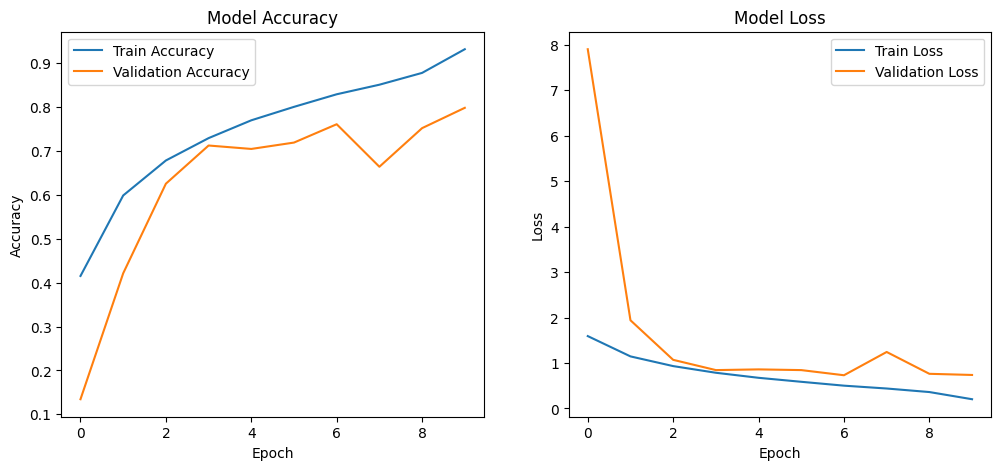

In [11]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1) 
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("Model Accuracy")
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


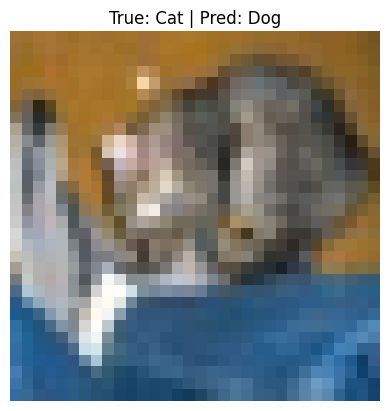

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


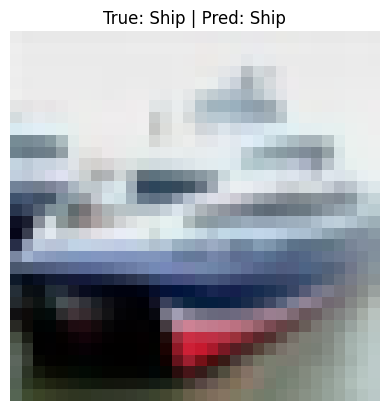

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


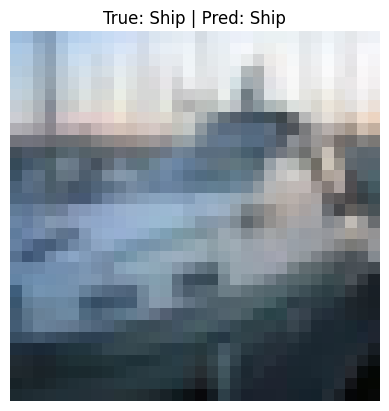

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


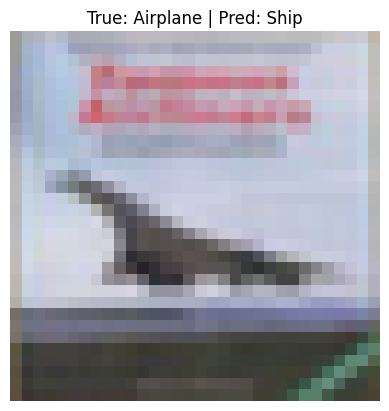

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


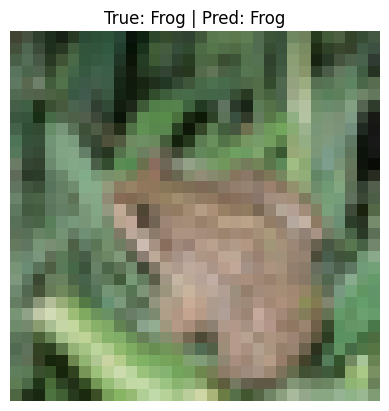

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


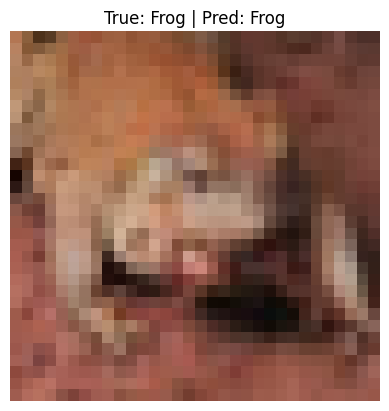

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


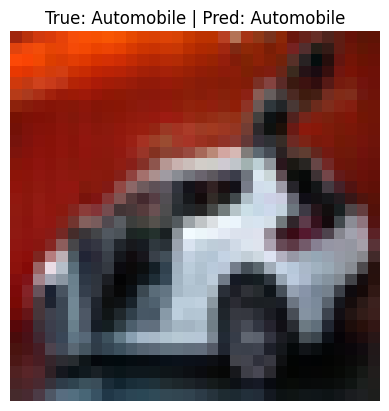

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


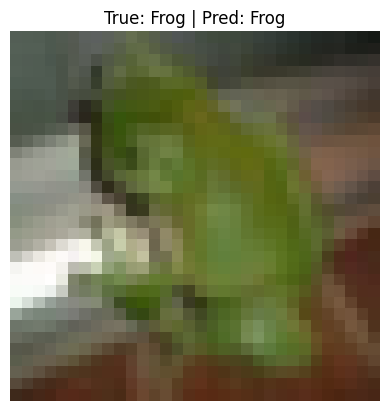

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


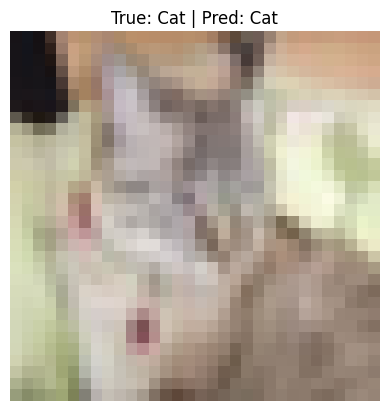

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


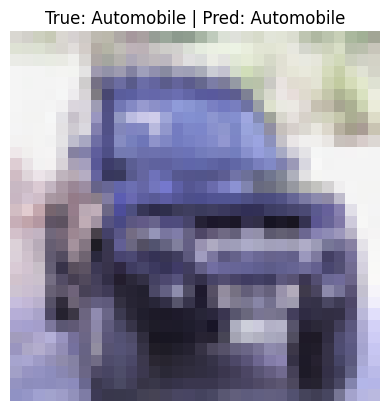

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


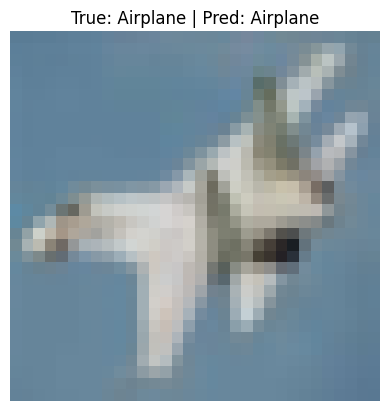

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


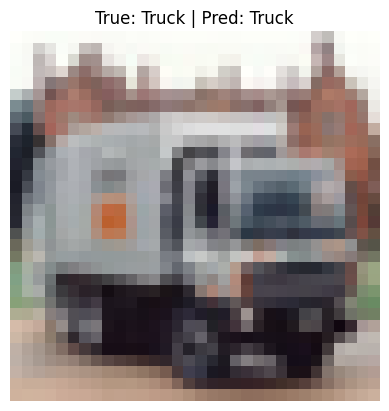

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


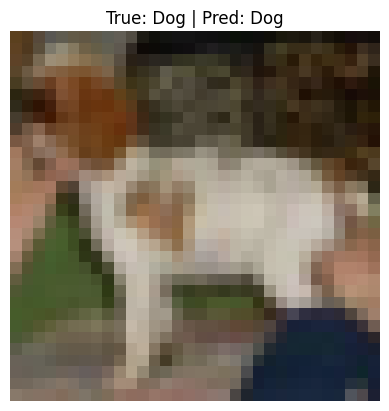

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


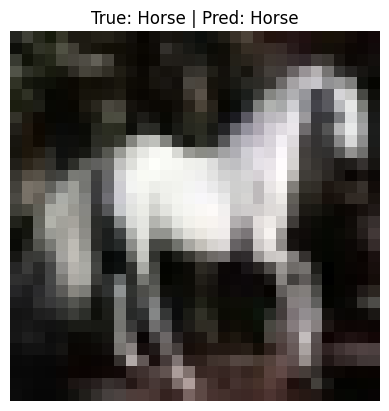

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


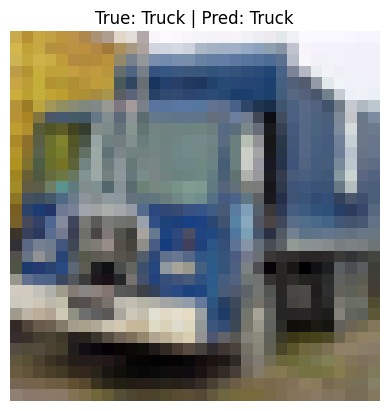

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


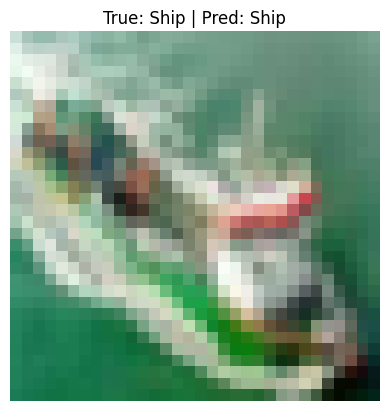

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


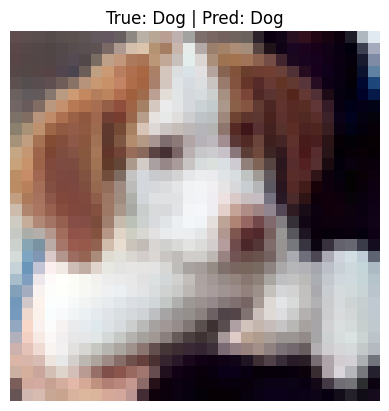

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


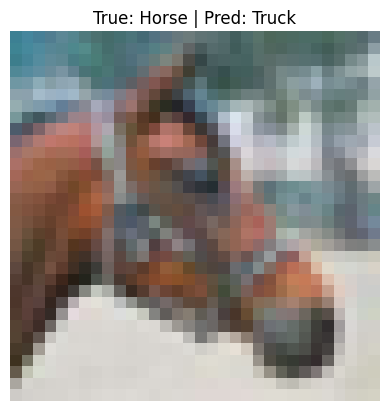

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


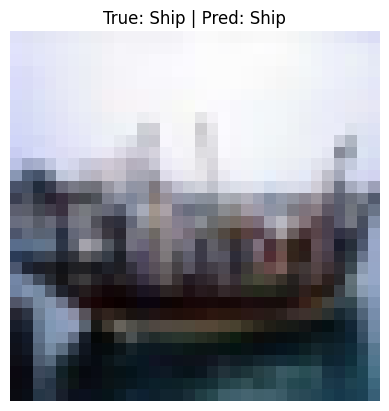

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


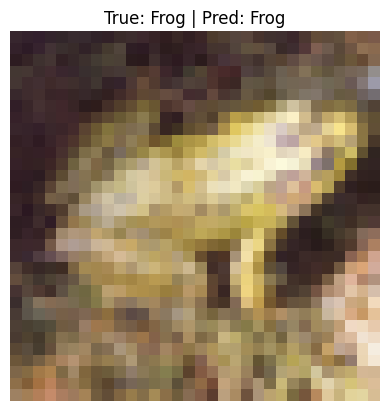

In [12]:
def plot_predictions2(index):
    img = x_test[index]
    true_label = class_names[np.argmax(y_test[index])]
    pred_probs = model.predict(np.expand_dims(img, axis=0))
    pred_label = class_names[np.argmax(pred_probs)]
    
    plt.imshow(img)
    plt.title(f"True: {true_label} | Pred: {pred_label}")
    plt.axis('off')
    plt.show()


for i in range(20):
    plot_predictions2(i)